# Ай сайынғы бұзылу қаупі

Бұл есепте кепілдіктегі тауарлардың бір ай ішінде бұзылу ықтималдығын және соған байланысты шығынды бағалаймыз.

Екі модель қарастырылады:

- Пуассон үлестірімі — бір айда қанша бұзылу болуы мүмкін екенін бағалау үшін;
- биномдық үлестірім — `n` тауардың ішінен кемінде біреуі бұзылу ықтималдығын есептеу үшін.

Жылдық қауіп $r_i$ болса, бір айлық қауіп мынадай болады:

$$p_i = \frac{r_i}{12}$$

Бір бұзылуға кететін шығынды тауар бағасының 35%-ы және £25 диагностика деп аламыз:

$$C_i = 0.35 \cdot \text{баға}_i + 25$$

In [6]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
rng = np.random.default_rng(42)

# Әр жолда: атауы, жылдық қауіп, бағасы
items = [
    ['Ноутбук', 0.16, 1200],
    ['Шаңсорғыш', 0.22, 450],
    ['Сағат', 0.14, 280],
    ['Монитор', 0.13, 520],
    ['Құлаққап', 0.17, 180],
    ['Велосипед', 0.20, 900],
]

repair_rate = 0.35
diagnosis_cost = 25

# Айлық қауіп пен бір бұзылудың бағасын есептейміз.
monthly_risks = np.array([item[1] / 12 for item in items])
repair_costs = np.array([item[2] * repair_rate + diagnosis_cost for item in items])

n = len(items)
p = monthly_risks.mean()
lam = monthly_risks.sum()

print(f'Тауар саны: n = {n}')
print(f'Орташа айлық қауіп: p = {p:.4f} ({p:.2%})')
print(f'Пуассон параметрі: lambda = {lam:.4f}')

Тауар саны: n = 6
Орташа айлық қауіп: p = 0.0142 (1.42%)
Пуассон параметрі: lambda = 0.0850


## Кемінде бір бұзылу ықтималдығы

Пуассон үлестірімінде $X$ — бір айдағы бұзылу саны. Оның параметрі:

$$\lambda = p_1 + p_2 + \dots + p_n$$

Дәл $k$ бұзылу ықтималдығы:

$$P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!}$$

Бізге көбіне кемінде бір бұзылу ықтималдығы керек:

$$P(X\ge 1)=1-e^{-\lambda}$$

Биномдық модельде барлық тауардың орташа айлық қаупін $p$ деп аламыз. Сонда:

$$P(Y\ge 1)=1-(1-p)^n$$

Екі формула бір сұраққа жауап береді, сондықтан нәтижелерді салыстыруға болады.

In [7]:
# Пуассон моделі
poisson_zero = math.exp(-lam)
poisson_at_least_one = 1 - poisson_zero

# Биномдық модель
binomial_at_least_one = 1 - (1 - p) ** n

# Күтілетін бұзылу саны мен күтілетін шығын
expected_breakdowns = lam
expected_cost = sum(monthly_risks * repair_costs)

# Қарапайым 95% резерв бағасы
reserve_breakdowns = math.ceil(lam + 1.645 * math.sqrt(lam))
reserve_cost = reserve_breakdowns * repair_costs.mean()

print(f'Пуассон: кемінде бір бұзылу = {poisson_at_least_one:.2%}')
print(f'Биномдық модель: кемінде бір бұзылу = {binomial_at_least_one:.2%}')
print(f'Күтілетін бұзылу саны = {expected_breakdowns:.3f}')
print(f'Күтілетін айлық шығын = £{expected_cost:.2f}')
print(f'95% резерв: {reserve_breakdowns} бұзылу, шамамен £{reserve_cost:.2f}')

Пуассон: кемінде бір бұзылу = 8.15%
Биномдық модель: кемінде бір бұзылу = 8.20%
Күтілетін бұзылу саны = 0.085
Күтілетін айлық шығын = £19.87
95% резерв: 1 бұзылу, шамамен £230.92


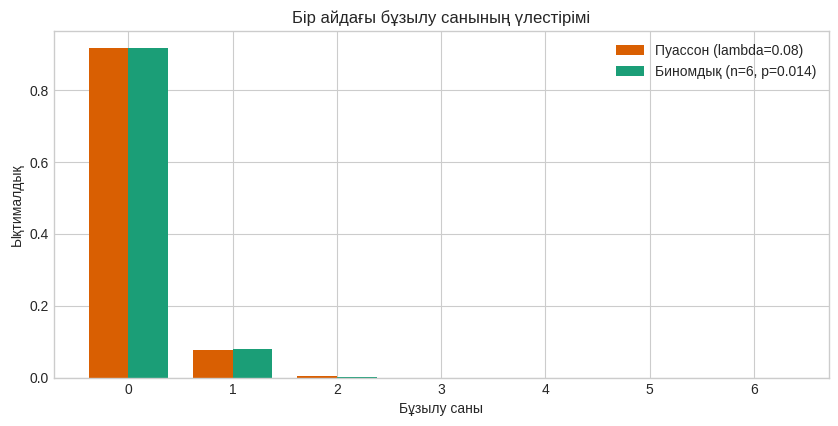

In [8]:
# Екі үлестірудің ықтималдықтарын есептейтін шағын функциялар
def poisson_probability(k, rate):
    return math.exp(-rate) * rate ** k / math.factorial(k)


def binomial_probability(k, trials, probability):
    return math.comb(trials, k) * probability ** k * (1 - probability) ** (trials - k)

number_of_breakdowns = np.arange(0, 7)
poisson_values = [poisson_probability(k, lam) for k in number_of_breakdowns]
binomial_values = [binomial_probability(k, n, p) for k in number_of_breakdowns]

plt.figure(figsize=(10, 4.5))
width = 0.38
plt.bar(number_of_breakdowns - width / 2, poisson_values, width, label=f'Пуассон (lambda={lam:.2f})', color='#d95f02')
plt.bar(number_of_breakdowns + width / 2, binomial_values, width, label=f'Биномдық (n={n}, p={p:.3f})', color='#1b9e77')
plt.title('Бір айдағы бұзылу санының үлестірімі')
plt.xlabel('Бұзылу саны')
plt.ylabel('Ықтималдық')
plt.xticks(number_of_breakdowns)
plt.legend()
plt.show()

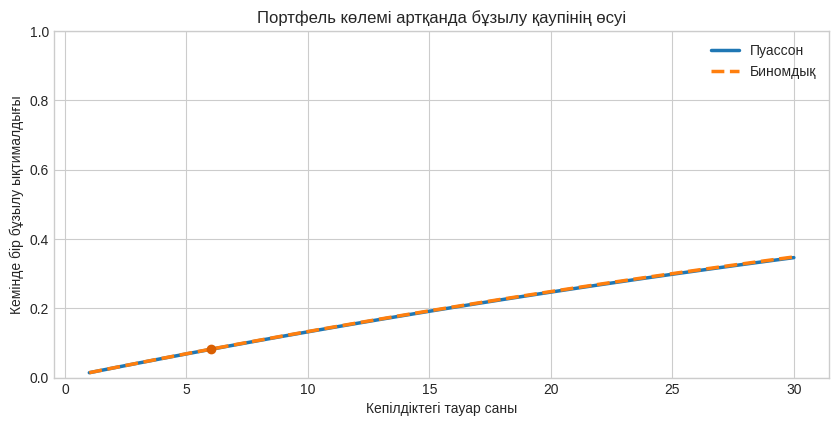

In [9]:
# Тауар саны көбейгенде кемінде бір бұзылу қаупі қалай өседі?
portfolio_sizes = np.arange(1, 31)
poisson_risk = 1 - np.exp(-portfolio_sizes * p)
binomial_risk = 1 - (1 - p) ** portfolio_sizes

plt.figure(figsize=(10, 4.5))
plt.plot(portfolio_sizes, poisson_risk, linewidth=2.5, label='Пуассон')
plt.plot(portfolio_sizes, binomial_risk, '--', linewidth=2.5, label='Биномдық')
plt.scatter([n], [poisson_at_least_one], color='#d95f02', zorder=3)
plt.title('Портфель көлемі артқанда бұзылу қаупінің өсуі')
plt.xlabel('Кепілдіктегі тауар саны')
plt.ylabel('Кемінде бір бұзылу ықтималдығы')
plt.ylim(0, 1)
plt.legend()
plt.show()

## Айлық шығынды бағалау

Әр тауардың өз қаупі $p_i$ және жөндеу шығыны $C_i$ бар. Сондықтан бір айға күтілетін шығын:

$$E(C)=\sum_{i=1}^{n}p_iC_i$$

Бұл — көптеген айдың орташа шығыны. Ал нақты бір айдағы шығын бұдан аз да, көп те болуы мүмкін.

Оны көру үшін 100 000 айды кездейсоқ түрде модельдейміз. Әр айда әр тауардың бұзылған-бұзылмағанын тексеріп, шығындарды қосамыз.

Теориялық күтілетін шығын: £19.87
Симуляцияның орташа шығыны: £19.91
Шығынның 95-процентилі: £182.50


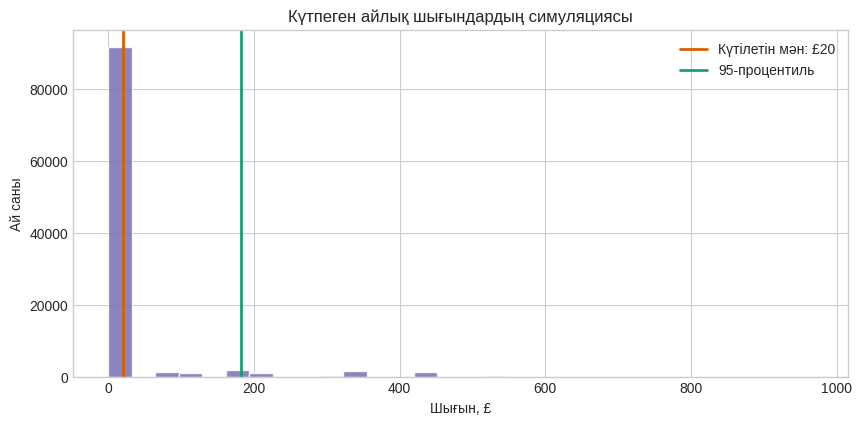

In [10]:
months = 100_000

# Әр ұяшықта: осы айда осы тауар бұзылды ма?
breakdowns = rng.random((months, n)) < monthly_risks
monthly_costs = breakdowns @ repair_costs

simulation_average = monthly_costs.mean()
simulation_95 = np.quantile(monthly_costs, 0.95)

print(f'Теориялық күтілетін шығын: £{expected_cost:.2f}')
print(f'Симуляцияның орташа шығыны: £{simulation_average:.2f}')
print(f'Шығынның 95-процентилі: £{simulation_95:.2f}')

plt.figure(figsize=(10, 4.5))
plt.hist(monthly_costs, bins=30, color='#7570b3', alpha=0.85, edgecolor='white')
plt.axvline(expected_cost, color='#d95f02', linewidth=2, label=f'Күтілетін мән: £{expected_cost:.0f}')
plt.axvline(simulation_95, color='#1b9e77', linewidth=2, label='95-процентиль')
plt.title('Күтпеген айлық шығындардың симуляциясы')
plt.xlabel('Шығын, £')
plt.ylabel('Ай саны')
plt.legend()
plt.show()

## Қорытынды

Бұл мысалда Пуассон және биномдық модельдер бір айда кемінде бір тауардың бұзылу қаупін шамамен бірдей көрсетті.

Негізгі формулалар:

$$P(X\ge 1)=1-e^{-\lambda}$$

$$P(Y\ge 1)=1-(1-p)^n$$

$$E(C)=\sum p_iC_i$$

Біздің деректер бойынша күтілетін айлық шығын шамамен £20 болды. Симуляциядағы орташа мән де осы санға жақын шықты. 95-процентиль қымбат айларға арналған резервті бағалауға көмектеседі.

Бұл тек мысалдық модель. Нақты бағалау үшін әр тауар бойынша жиналған бұзылу статистикасын пайдаланып, $p_i$ мәндерін жаңарту керек.